# Course in Python and AI at Lexicon
## Projekt work dataanalys

In [24]:
import matplotlib.pyplot as plt
import pandas as pd

from matplotlib.ticker import PercentFormatter

In [4]:
flights_original = pd.read_csv('data/flights.csv')
flights = flights_original.copy()
airports_original = pd.read_csv('data/airports.csv')
airports = airports_original.copy()

print(flights.shape)
print(flights.info())
print(flights.describe())
print()
print('-----------------------------------------')
print()
print(airports.shape)
print(airports.info())
print(airports.describe())


(20000, 5)
<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   date         20000 non-null  str  
 1   delay        20000 non-null  int64
 2   distance     20000 non-null  int64
 3   origin       20000 non-null  str  
 4   destination  20000 non-null  str  
dtypes: int64(2), str(3)
memory usage: 781.4 KB
None
              delay      distance
count  20000.000000  20000.000000
mean       7.703900    723.846700
std       31.318537    562.705585
min      -59.000000     30.000000
25%       -8.000000    309.000000
50%        0.000000    562.000000
75%       13.000000    978.000000
max      522.000000   4475.000000

-----------------------------------------

(3376, 7)
<class 'pandas.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   iata       3376 non

## The Data

The data comes from the Vega datasets on GitHub (https://vega.github.io/vega-datasets/). It seems to be the datasets 'flights_20k' and 'airports' we have been given here. The datasets are example data for the diagram tool Vega. The Vega project made this file as a demo for its charting tools, not to study delays. It is a sample of a larger file, and I do not know how it was chosen.

Flight delay statistics (20,000 rows) from U.S. Bureau of Transportation Statistics. Collected under regulatory reporting requirements, which mandate that qualifying airlines report on-time performance data to BTS. Date follows the format %Y-%m-%d %H:%M:%S, delay seems to be given in minutes. Licence for the data is unclear.

Airports in the United States and its territories, including major commercial, regional, and municipal airports. Contains information about each airport's location (latitude/longitude coordinates), identification codes, name, city, state, and country. While the exact generation source of this file is unknown, this data is consistent with files provided on a monthly frequency by the FAA's National Airspace System Resource. License: https://www.usa.gov/government-works .

### Sources

1. Vega datasets, metadata overview: https://vega.github.io/vega-datasets/metadata/
2. Vega datasets, airports: https://vega.github.io/vega-datasets/datasets/airports/

In [5]:
flights["date"].head(10)

0    2001-01-01 00:47:00
1    2001-01-01 01:10:00
2    2001-01-01 01:24:00
3    2001-01-01 01:39:00
4    2001-01-01 06:02:00
5    2001-01-01 06:05:00
6    2001-01-01 06:17:00
7    2001-01-01 06:22:00
8    2001-01-01 06:30:00
9    2001-01-01 06:35:00
Name: date, dtype: str

In [6]:
flights["date"] = pd.to_datetime(flights["date"], format="%Y-%m-%d %H:%M:%S", errors="coerce")

print(flights["date"].isna().sum())
print(flights["date"].min(), flights["date"].max())
print(flights["date"].dtype)

0
2001-01-01 00:47:00 2001-03-31 22:27:00
datetime64[us]


In [7]:
# Looking for the 12 missing Airport codes and cities

missing = airports[airports["city"].isna()]
print(missing[["iata", "name", "city", "state", "country"]])

     iata                          name city state  \
1136  CLD    MC Clellan-Palomar Airport  NaN   NaN   
1715  HHH                   Hilton Head  NaN   NaN   
2251  MIB                     Minot AFB  NaN   NaN   
2312  MQT      Marquette County Airport  NaN   NaN   
2752  RCA                 Ellsworth AFB  NaN   NaN   
2759  RDR               Grand Forks AFB  NaN   NaN   
2794  ROP                   Prachinburi  NaN   NaN   
2795  ROR              Babelthoup/Koror  NaN   NaN   
2900  SCE               University Park  NaN   NaN   
2964  SKA                 Fairchild AFB  NaN   NaN   
3001  SPN  Tinian International Airport  NaN   NaN   
3355  YAP             Yap International  NaN   NaN   

                             country  
1136                             USA  
1715                             USA  
2251                             USA  
2312                             USA  
2752                             USA  
2759                             USA  
2794                    

In [8]:
codes = ["CLD", "HHH", "MIB", "MQT", "RCA", "RDR", "SCE", "SKA", "ROP", "ROR", "SPN", "YAP"]

ourairports = pd.read_csv("data/ourairports_airports.csv", keep_default_na=False)

fill = ourairports[ourairports["iata_code"].isin(codes)].copy()
print(fill[["iata_code", "name", "municipality", "iso_region", "iso_country"]])

      iata_code                                  name        municipality  \
39277       CLD             McClellan-Palomar Airport            Carlsbad   
40368       HHH                   Hilton Head Airport  Hilton Head Island   
40854       MIB                  Minot Air Force Base               Minot   
42599       RCA              Ellsworth Air Force Base          Rapid City   
42611       RDR            Grand Forks Air Force Base         Grand Forks   
42747       MQT     Marquette Sawyer Regional Airport               Gwinn   
42807       SKA              Fairchild Air Force Base             Spokane   
43088       SCE        State College Regional Airport       State College   
53284       ROP            Rota International Airport         Rota Island   
53285       SPN          Saipan International Airport    I Fadang, Saipan   
54853       ROR  Roman Tmetuchl International Airport   Babelthuap Island   
54855       YAP             Yap International Airport          Yap Island   

In [9]:
codes = ["CLD", "HHH", "MIB", "MQT", "RCA", "RDR", "SCE", "SKA", "ROP", "ROR", "SPN", "YAP"]

ourairports = pd.read_csv("data/ourairports_airports.csv", keep_default_na=False)

fill = ourairports[ourairports["iata_code"].isin(codes)].copy()
fill["state"] = fill["iso_region"].where(fill["iso_country"] == "US").str.replace("US-", "", regex=False)
fill = fill.set_index("iata_code")

print(fill[["name", "municipality", "iso_country", "state"]])

                                           name        municipality  \
iata_code                                                             
CLD                   McClellan-Palomar Airport            Carlsbad   
HHH                         Hilton Head Airport  Hilton Head Island   
MIB                        Minot Air Force Base               Minot   
RCA                    Ellsworth Air Force Base          Rapid City   
RDR                  Grand Forks Air Force Base         Grand Forks   
MQT           Marquette Sawyer Regional Airport               Gwinn   
SKA                    Fairchild Air Force Base             Spokane   
SCE              State College Regional Airport       State College   
ROP                  Rota International Airport         Rota Island   
SPN                Saipan International Airport    I Fadang, Saipan   
ROR        Roman Tmetuchl International Airport   Babelthuap Island   
YAP                   Yap International Airport          Yap Island   

     

In [10]:
print("Before:", airports["city"].isna().sum(), airports["state"].isna().sum())

airports["city"] = airports["city"].fillna(airports["iata"].map(fill["municipality"]))
airports["state"] = airports["state"].fillna(airports["iata"].map(fill["state"]))

print("After:", airports["city"].isna().sum(), airports["state"].isna().sum())
print(airports[airports["iata"] == "MQT"])

Before: 12 12
After: 0 4
     iata                      name   city state country   latitude  longitude
2312  MQT  Marquette County Airport  Gwinn    MI     USA  46.353639 -87.395361


In [11]:
# Chcking for duplicates before merge
print("Duplicate iata in airports:", airports["iata"].duplicated().sum())
print("Duplicate rows in flights:", flights.duplicated().sum())

# An empty set means every code in flights exists in airports.
print("Origin not in airports:", set(flights["origin"]) - set(airports["iata"])) # 
print("Destination not in airports:", set(flights["destination"]) - set(airports["iata"]))

Duplicate iata in airports: 0
Duplicate rows in flights: 0
Origin not in airports: set()
Destination not in airports: set()


In [12]:
airports_small = airports[["iata", "city", "state", "latitude", "longitude"]]

departure_info = airports_small.add_prefix("departure_")
arrival_info = airports_small.add_prefix("arrival_")

flights_merged = flights.merge(
    departure_info, left_on="origin", right_on="departure_iata",
    how="left", validate="many_to_one"
).drop(columns="departure_iata")

flights_merged = flights_merged.merge(
    arrival_info, left_on="destination", right_on="arrival_iata",
    how="left", validate="many_to_one"
).drop(columns="arrival_iata")

print("Rows before:", len(flights))
print("Rows after:", len(flights_merged))
print(flights_merged.isna().sum())

Rows before: 20000
Rows after: 20000
date                   0
delay                  0
distance               0
origin                 0
destination            0
departure_city         0
departure_state        0
departure_latitude     0
departure_longitude    0
arrival_city           0
arrival_state          0
arrival_latitude       0
arrival_longitude      0
dtype: int64


In [13]:
# Flights where departure and arrival are the same airport
print("Same origin and destination:", (flights_merged["origin"] == flights_merged["destination"]).sum())

# Very long delays
print("Delay over 300 minutes:", (flights_merged["delay"] > 300).sum())
print(flights_merged.nlargest(5, "delay")[["date", "delay", "distance", "origin", "destination"]])

# Shortest and longest distances
print(flights_merged["distance"].describe())


Same origin and destination: 0
Delay over 300 minutes: 10
                     date  delay  distance origin destination
12157 2001-02-25 14:50:00    522       116    BMI         ORD
9185  2001-02-11 16:02:00    518       237    TUL         DFW
8755  2001-02-09 13:30:00    509       237    MCI         STL
16452 2001-03-16 14:50:00    396       929    TPA         DFW
7994  2001-02-05 23:57:00    390       160    PVD         EWR
count    20000.000000
mean       723.846700
std        562.705585
min         30.000000
25%        309.000000
50%        562.000000
75%        978.000000
max       4475.000000
Name: distance, dtype: float64


In [14]:
import numpy as np

def haversine_miles(lat1, lon1, lat2, lon2):
    # Distance between two points on the earth, in miles
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 3958.8 * np.arcsin(np.sqrt(a))

flights_merged["distance_calc"] = haversine_miles(
    flights_merged["departure_latitude"], flights_merged["departure_longitude"],
    flights_merged["arrival_latitude"], flights_merged["arrival_longitude"],
)
flights_merged["distance_diff"] = flights_merged["distance"] - flights_merged["distance_calc"]

print(flights_merged["distance_diff"].describe())
print(flights_merged.loc[flights_merged["distance_diff"].abs().nlargest(5).index,
                         ["origin", "destination", "distance", "distance_calc", "distance_diff"]])

count    20000.000000
mean         0.677262
std          1.676384
min         -4.953324
25%         -0.303067
50%          0.445735
75%          1.442038
max          7.345223
Name: distance_diff, dtype: float64
      origin destination  distance  distance_calc  distance_diff
13098    ANC         ORD      2846    2838.654777       7.345223
14047    ORD         ANC      2846    2838.654777       7.345223
4958     SEA         BOS      2496    2488.949892       7.050108
1368     JFK         SJC      2570    2563.067366       6.932634
1447     SJC         JFK      2570    2563.067366       6.932634


In [15]:
import numpy as np

def haversine_miles(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 3958.8 * np.arcsin(np.sqrt(a))

flights_merged["distance_calc"] = haversine_miles(
    flights_merged["departure_latitude"], flights_merged["departure_longitude"],
    flights_merged["arrival_latitude"], flights_merged["arrival_longitude"],
)
flights_merged["distance_diff"] = flights_merged["distance"] - flights_merged["distance_calc"]

print(flights_merged["distance_diff"].describe())
print(flights_merged.loc[flights_merged["distance_diff"].abs().nlargest(5).index,
                         ["origin", "destination", "distance", "distance_calc", "distance_diff"]])

count    20000.000000
mean         0.677262
std          1.676384
min         -4.953324
25%         -0.303067
50%          0.445735
75%          1.442038
max          7.345223
Name: distance_diff, dtype: float64
      origin destination  distance  distance_calc  distance_diff
13098    ANC         ORD      2846    2838.654777       7.345223
14047    ORD         ANC      2846    2838.654777       7.345223
4958     SEA         BOS      2496    2488.949892       7.050108
1368     JFK         SJC      2570    2563.067366       6.932634
1447     SJC         JFK      2570    2563.067366       6.932634


Seems like the distances are correct, with only small differences compared to distances calculated from coordinates. Unit is miles.

In [16]:
# Ny kolumn med avstånd i km

flights_merged["distance_km"] = (flights_merged["distance"] * 1.609344).round().astype(int)

print(flights_merged[["origin", "destination", "distance", "distance_km"]].head())

  origin destination  distance  distance_km
0    DTW         LAS      1750         2816
1    HNL         SFO      2399         3861
2    LAS         OAK       407          655
3    LAS         PHX       256          412
4    MHT         BWI       377          607


In [17]:
# Eamining delays
delay = flights_merged["delay"]
hour = flights_merged["date"].dt.hour

# The delay itself
print(delay.describe())
print("Median:", delay.median())
print("Share over 15 minutes:", round((delay > 15).mean(), 3))

# Correlation with distance and hour (1 = perfect, 0 = none)
print("Delay and distance_km:", round(delay.corr(flights_merged["distance_km"]), 3))
print("Delay and hour:", round(delay.corr(hour), 3))

# Delay for each hour of the day
print(delay.groupby(hour).agg(["mean", "median", "count"]).round(1))

count    20000.000000
mean         7.703900
std         31.318537
min        -59.000000
25%         -8.000000
50%          0.000000
75%         13.000000
max        522.000000
Name: delay, dtype: float64
Median: 0.0
Share over 15 minutes: 0.217
Delay and distance_km: -0.022
Delay and hour: 0.158
       mean  median  count
date                      
0      31.8    10.0     70
1      26.2     5.0     53
2      57.8    12.0      9
3     121.0   121.0      2
4      -3.0    -3.0      1
5      -3.5    -4.0    240
6      -1.6    -3.0   1313
7      -0.2    -3.0   1280
8       0.9    -2.0   1323
9       3.8    -2.0   1266
10      5.3    -1.0   1094
11      4.7     0.0   1225
12      9.4     0.0   1229
13      6.6     0.0   1307
14      8.7     1.0   1117
15      8.7     1.0   1156
16      9.3     0.0   1165
17      9.8     2.0   1374
18     10.9     1.0   1206
19     14.0     2.0   1244
20     11.7     1.0    988
21     19.5     6.0    711
22     23.0     5.0    456
23     26.5     5.0    171


No correlation between delays and distance. Morning delays are shorter, and delays probably add up during the day, but the correlation between delay and hour is low. It is unclear what happens to delays that pass into the next day. Long delays during the night are few, skew the statistics, and probably come from the day before.

In [18]:
late = flights_merged["delay"] > 15

by_airport = flights_merged.groupby("origin").agg(
    flights=("delay", "size"),
    mean_delay=("delay", "mean"),
    median_delay=("delay", "median"),
)
by_airport["share_late"] = late.groupby(flights_merged["origin"]).mean()

# Keep only airports with at least 100 flights
by_airport = by_airport[by_airport["flights"] >= 100].round(2)

print("Airports kept:", len(by_airport))
print(by_airport.sort_values("mean_delay", ascending=False).head(10))
print(by_airport.sort_values("share_late", ascending=False).head(10))

Airports kept: 52
        flights  mean_delay  median_delay  share_late
origin                                               
JFK         200       16.20           3.0        0.34
SEA         339       13.34           2.0        0.31
MIA         294       13.12           4.0        0.30
SMF         121       13.12           4.0        0.25
BOS         369       12.52           2.0        0.29
PHX         633       12.05           4.0        0.26
DEN         452       11.90           1.0        0.27
MSY         176       11.56           1.5        0.24
TPA         255       11.29           2.0        0.26
PDX         172       10.81           1.0        0.22
        flights  mean_delay  median_delay  share_late
origin                                               
JFK         200       16.20           3.0        0.34
SEA         339       13.34           2.0        0.31
MIA         294       13.12           4.0        0.30
BOS         369       12.52           2.0        0.29
DEN       

In [21]:
by_airport["margin"] = (
    1.96 * (by_airport["share_late"] * (1 - by_airport["share_late"]) / by_airport["flights"]) ** 0.5
).round(3)

print(by_airport.sort_values("share_late", ascending=False).head(10))

        flights  mean_delay  median_delay  share_late  margin
origin                                                       
JFK         200       16.20           3.0        0.34   0.066
SEA         339       13.34           2.0        0.31   0.049
MIA         294       13.12           4.0        0.30   0.052
BOS         369       12.52           2.0        0.29   0.046
DEN         452       11.90           1.0        0.27   0.041
IND         131        6.89           2.0        0.27   0.076
PHX         633       12.05           4.0        0.26   0.034
LAX         777        9.38           0.0        0.26   0.031
TPA         255       11.29           2.0        0.26   0.054
STL         550        9.55           2.0        0.26   0.037


Share late, all flights: 0.228


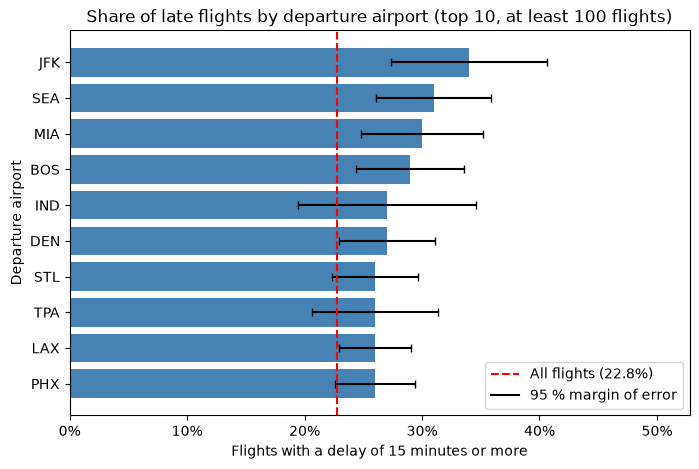

In [28]:
from matplotlib.lines import Line2D

top10 = by_airport.sort_values("share_late", ascending=False).head(10).sort_values("share_late")
overall = (flights_merged["delay"] >= 15).mean()
print("Share late, all flights:", round(overall, 3))

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top10.index, top10["share_late"], xerr=top10["margin"], color="steelblue", capsize=3)
ax.axvline(overall, color="red", linestyle="--")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Share of late flights by departure airport (top 10, at least 100 flights)")
ax.set_xlabel("Flights with a delay of 15 minutes or more")
ax.set_ylabel("Departure airport")

# Legend with one entry for each kind of line
handles = [
    Line2D([0], [0], color="red", linestyle="--", label=f"All flights ({overall:.1%})"),
    Line2D([0], [0], color="black", label="95 % margin of error"),
]
ax.set_xlim(0, (top10["share_late"] + top10["margin"]).max() * 1.3)
ax.legend(handles=handles, loc="lower right")
plt.show()

JFK has the highest share of delayed flights (15 minutes or more) among airports with at least 100 flights: 34 % of the flights from JFK. The mean delay is 16.2 minutes. A few very long delays raise the mean. The median is only 3 minutes, which is not a delay under this definition.

The margin of error is large, almost 7 percentage points for JFK, so JFK cannot be singled out. SEA, MIA and BOS have a similar share of late flights, and their ranges overlap with JFK's. The order of the top ten airports is uncertain. With 131 to 777 flights per airport, the margins of error (3 to 8 percentage points) are as large as the differences between them. I can say that these airports have a high share of late flights compared to the rest, but not which one is worst.

Margin of error for JFK:

$\displaystyle \text{margin} = 1.96 \times \sqrt{\frac{0.34 \times (1-0.34)}{200}} = 1.96 \times \sqrt{0.001122} \approx 1.96 \times 0.0335 \approx 0.066$